# Семинар 6. Эмбеддинги слов и классификация текстов

На занятии мы попробуем на практике то, что изучили на лекции - посмотрим на операции с эмбеддингами, попробуем самостоятельно обучить word2vec, а также решить с их помощью прикладную задачу классификации текстов. Кроме того, посмотрим на нейросетевой подход к решению данной задачи, а именно, как использовать MLP для обработки текстов.

Для загрузки предобученных эмбеддингов и датасета IMDb нужен доступ к сети. Обучающие ячейки можно запускать на GPU; на CPU уменьшите число эпох.

## Источники

- [Конспект по основам NLP](https://github.com/mmp-practicum-team/mmp_practicum_spring_2024/blob/main/Seminars/Seminar%2007/%D0%AF%D0%B7%D1%8B%D0%BA%D0%BE%D0%B2%D1%8B%D0%B5%20%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8.%20Torchtext.ipynb)

- [Документация gensim](https://radimrehurek.com/gensim/models/word2vec.html)

- **UMAP**: [Leland McInnes et al., 2018](https://arxiv.org/abs/1802.03426), примерно 22 тысячи цитирований

- [Документация umap](https://umap-learn.readthedocs.io/en/latest/)

- [Выделение смысловых компонент слов с помощью Lasso](https://lars76.github.io/2021/06/16/operations-contextual-embeddings.html)

- [Датасет рецензий с Imdb](https://ai.stanford.edu/~amaas/data/sentiment/).

- [Документация CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)

- [Примеры датасетов для классификации текстов](https://lena-voita.github.io/nlp_course/text_classification.html#dataset_examples)

- [Документация fasttext](https://fasttext.cc/docs/en/python-module.html)

- [Документация tokenizers](https://huggingface.co/docs/tokenizers/index)

- [Документация datasets](https://huggingface.co/docs/datasets/index)

- Для большинства изображений указан источник, откуда оно взято, как правило, являющийся статьей

## Подготовка окружения

In [1]:
#!pip install gensim
#!pip install catboost
#!pip install tokenizers

In [2]:
import os
import numpy as np
import random

import matplotlib_inline
import matplotlib.pyplot as plt

%matplotlib inline


np.random.seed(52)
random.seed(52)

## Модели эмбеддингов на основе предсказаний

Мы будем пользоваться библиотекой [gensim](https://radimrehurek.com/gensim/models/word2vec.html), так как в ней удобно реализованы различные методы обучения эмбеддингов: `word2vec`.

Кроме того, существуют уже предобученные модели, что позволяет в несколько строк получить качественные эмбеддинги. Посмотрим на список доступных моделей ниже.

In [3]:
import gensim
import gensim.downloader

In [4]:
print(list(gensim.downloader.info()['models'].keys()))

['fasttext-wiki-news-subwords-300', 'conceptnet-numberbatch-17-06-300', 'word2vec-ruscorpora-300', 'word2vec-google-news-300', 'glove-wiki-gigaword-50', 'glove-wiki-gigaword-100', 'glove-wiki-gigaword-200', 'glove-wiki-gigaword-300', 'glove-twitter-25', 'glove-twitter-50', 'glove-twitter-100', 'glove-twitter-200', '__testing_word2vec-matrix-synopsis']


Для наглядности мы будем использовать `word2vec-ruscorpora-300`, так как это обученные эмбеддинги для русского языка.

In [5]:
word2vec_rus = gensim.downloader.load('word2vec-ruscorpora-300')

In [6]:
print(f"Всего слов {len(word2vec_rus.index_to_key)}")
print(f"Размерность {word2vec_rus.vector_size}")

print(f"Примеры слов:", ', '.join(word2vec_rus.index_to_key[:10]))


Всего слов 184973
Размерность 300
Примеры слов: весь_DET, человек_NOUN, мочь_VERB, год_NOUN, сказать_VERB, время_NOUN, говорить_VERB, становиться_VERB, знать_VERB, самый_DET


Можно заметить, что каждое слово имеет суффикс, который отвечает за часть речи (NOUN - существительное, VERB - глагол и тд). Задача определения части речи называется `part-of-speech tagging`.

Красивую визуализацию можно найти [тут](https://rusvectores.org/ru/visual/).

Мы же попробуем визуализировать и изучить интересные свойства самостоятельно.

## Операции над эмбеддингами

В моделях из библиотеки `gensim` реализован автоматический поиск наиболее похожих слов, то есть поиск слов, чьи эмбеддинги наиболее близки к эмбеддингу исходного.

In [7]:
a = word2vec_rus.get_vector('холод_NOUN')

word2vec_rus.similar_by_vector(a)

[('холод_NOUN', 1.0),
 ('стужа_NOUN', 0.754147469997406),
 ('мороз_NOUN', 0.7195620536804199),
 ('сырость_NOUN', 0.6915026307106018),
 ('мерзнуть_VERB', 0.66225665807724),
 ('тепло_NOUN', 0.6225269436836243),
 ('зябнуть_VERB', 0.6161022186279297),
 ('жара_NOUN', 0.6121419668197632),
 ('замерзать_VERB', 0.6117622256278992),
 ('знобить_VERB', 0.5948620438575745)]

Кроме того, мы можем производить над эмбеддингами арифметические операции.

In [8]:
a = word2vec_rus.get_vector('король_NOUN')
b = word2vec_rus.get_vector('мужчина_NOUN')

word2vec_rus.similar_by_vector(a - b)

[('король_NOUN', 0.6571975350379944),
 ('королевство_NOUN', 0.45206212997436523),
 ('королевский_ADJ', 0.43994268774986267),
 ('максимилианов_NOUN', 0.4211024045944214),
 ('кельский_ADJ', 0.4128030240535736),
 ('каролус_NOUN', 0.4126133322715759),
 ('рагоци_NOUN', 0.40673771500587463),
 ('герцог_NOUN', 0.4043634533882141),
 ('королева_NOUN', 0.40316256880760193),
 ('дурлахский_ADJ', 0.40299752354621887)]

In [9]:
c = word2vec_rus.get_vector('женщина_NOUN')

word2vec_rus.similar_by_vector(a - b + c)

[('король_NOUN', 0.880538821220398),
 ('королева_NOUN', 0.7313904166221619),
 ('герцог_NOUN', 0.6502388715744019),
 ('принцесса_NOUN', 0.6266285181045532),
 ('герцогиня_NOUN', 0.6240381598472595),
 ('королевство_NOUN', 0.6094207167625427),
 ('зюдерманландский_ADJ', 0.6084389686584473),
 ('дурлахский_ADJ', 0.6081665754318237),
 ('ульрик::элеонора_NOUN', 0.6073107123374939),
 ('максимилианов_NOUN', 0.6057004332542419)]

In [10]:
a = word2vec_rus.get_vector('москва_NOUN')
b = word2vec_rus.get_vector('россия_NOUN')
c = word2vec_rus.get_vector('германия_NOUN')

word2vec_rus.similar_by_vector(a - b + c)

[('берлин_NOUN', 0.7166863679885864),
 ('москва_NOUN', 0.6859815716743469),
 ('германия_NOUN', 0.6379822492599487),
 ('мюнхен_NOUN', 0.6141613721847534),
 ('гамбург_NOUN', 0.5910832285881042),
 ('дрезден_NOUN', 0.5751316547393799),
 ('бабельсберг_NOUN', 0.5680847764015198),
 ('париж_NOUN', 0.5643576979637146),
 ('лейпциг_NOUN', 0.555885910987854),
 ('карлсхорст_NOUN', 0.553295373916626)]

Чуть аккуратней этот функционал уже реализован в библиотеке.

In [11]:
word2vec_rus.most_similar(
    positive=['москва_NOUN', 'германия_NOUN'],
    negative=['россия_NOUN']
)

[('берлин_NOUN', 0.7166863679885864),
 ('мюнхен_NOUN', 0.6141613721847534),
 ('гамбург_NOUN', 0.5910832285881042),
 ('дрезден_NOUN', 0.5751316547393799),
 ('бабельсберг_NOUN', 0.5680847764015198),
 ('париж_NOUN', 0.5643577575683594),
 ('лейпциг_NOUN', 0.555885910987854),
 ('карлсхорст_NOUN', 0.553295373916626),
 ('билефельд_NOUN', 0.5470367670059204),
 ('дуйсбург_NOUN', 0.5449016094207764)]

У некоторых слов много значений, поэтому мы можем найти достаточно разные слова по смыслу.

In [12]:
word2vec_rus.similar_by_vector('ручка_NOUN')

[('ножка_NOUN', 0.6115206480026245),
 ('рукоятка_NOUN', 0.6041494607925415),
 ('рука_NOUN', 0.562088668346405),
 ('пальчик_NOUN', 0.5414899587631226),
 ('рычажок_NOUN', 0.5311201214790344),
 ('ноготочка_NOUN', 0.525374710559845),
 ('головка_NOUN', 0.5234273076057434),
 ('дверной_ADJ', 0.5118671655654907),
 ('щечка_NOUN', 0.508470356464386),
 ('поприседать_VERB', 0.5080488324165344)]

Кроме того, можно быстро находить синонимы.

In [13]:
word2vec_rus.similar_by_vector('красивый_ADJ')

[('красиво_ADV', 0.6824069619178772),
 ('некрасивый_ADJ', 0.6662992835044861),
 ('нарядный_ADJ', 0.6605890989303589),
 ('прекрасный_ADJ', 0.6481409668922424),
 ('элегантный_ADJ', 0.6363735198974609),
 ('красавец_NOUN', 0.6171321868896484),
 ('очаровательный_ADJ', 0.6072524189949036),
 ('прелестный_ADJ', 0.606392502784729),
 ('хорошенький_ADJ', 0.6016284227371216),
 ('изящный_ADJ', 0.6009820699691772)]

Мы ожидаем, что для разных по смыслу слов расстояние между эмбеддингами будет больше, чем между похожими.

In [14]:
word2vec_rus.distance('щука_NOUN', 'тумбочка_NOUN')

np.float32(0.8575244)

In [15]:
word2vec_rus.distance('щука_NOUN', 'окунь_NOUN')

np.float32(0.27397376)

In [16]:
word2vec_rus.distance('щука_NOUN', 'карась_NOUN')

np.float32(0.31555992)

In [17]:
word2vec_rus.distance('щука_NOUN', 'рыба_NOUN')

np.float32(0.28943992)

Однако не стоит забывать, что эмбеддинги не идеальные, поэтому иногда возникают странные ситуации.

In [18]:
word2vec_rus.distance('щука_NOUN', 'вода_NOUN')

np.float32(0.64794594)

В случае более хороших эмбеддингов, полученных из нейронных сетей, можно даже обучать линейные модели для поиска "смысловых компонент" слова. Подробнее можно изучить [по ссылке](https://lars76.github.io/2021/06/16/operations-contextual-embeddings.html).

## Классификация

Мы хотим использовать векторные представления слов для алгоритмов машинного обучения или нейронных сетей. Прежде чем перейти к нейронным сетям, нам нужны бейзлайны - то есть то, с чем будем сравниваться. Сначала проверим, как работают стандартные алгоритмы машинного обучения на эмбеддингах.

Мы будем решать задачу бинарной классификации для [датасета рецензий с Imdb](https://ai.stanford.edu/~amaas/data/sentiment/).

В качестве базовой модели будем использовать [CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier).

Подробный список классических датасетов для классификации текста можно посмотреть [здесь](https://lena-voita.github.io/nlp_course/text_classification.html#dataset_examples).

In [19]:
"""
if not os.path.exists("aclImdb"):
    if not os.path.exists("aclImdb_v1.tar.gz"):
        ! wget https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
    ! tar -xf aclImdb_v1.tar.gz
"""

'\nif not os.path.exists("aclImdb"):\n    if not os.path.exists("aclImdb_v1.tar.gz"):\n        ! wget https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz\n    ! tar -xf aclImdb_v1.tar.gz\n'

Мы не будем усердно заниматься предобработкой, так как наша цель - именно сравнить методы, а не добиться более высокого качества. В качестве предобработки мы приведем все символы к нижнему регистру.

In [20]:
#!pip3 install openpyxl
import pandas as pd
def preprocess(l):
    return l.lower()

filename='markup_21_10_2026_priv.xlsx'
df = pd.read_excel(filename)

In [21]:
def get_dataset(split='train', df=None, 
                date_train_start = '2025-03-10',
                date_train_end = '2026-10-13',
                date_val_start = '2026-10-14',
                date_val_end = '2026-10-18',
                date_test_start = '2026-10-19', 
                date_test_end = '2026-12-10'):
    #read_excel
    if split == 'train':
        df = df[df['record_date'] >= date_train_start]
        df = df[df['record_date'] <= date_train_end]
        df_trues = df[df['is_fraud'] == 1]
        df_falses = df[df['is_fraud'] == 0]
        #filter first 2000 trues
        df_trues = df_trues.sample(frac=1, random_state=42)
        df_trues = df_trues[:20000]
        
        #filter first 20000 falses
        df_falses = df_falses.sample(frac=1, random_state=42)
        df_falses = df_falses[:80000]
        
        #concat
        df = pd.concat([df_trues, df_falses])
    elif split == 'val':
        df = df[df['record_date'] >= date_val_start]
        df = df[df['record_date'] <= date_val_end]
    else:
        df = df[df['record_date'] >= date_test_start]
        df = df[df['record_date'] <= date_test_end]
    
    X = df['original_text'].values
    y = df['is_fraud'].values
    print(f"Объектов положительного класса {len(y[y == 1])}")
    print(f"Объектов отрицательного класса {len(y[y == 0])}")
    print(f"Соотношение классов {len(y[y == 1]) / len(y[y == 0])}")

    return X, y

In [22]:
X_train, y_train = get_dataset(split='train',df=df)

Объектов положительного класса 20000
Объектов отрицательного класса 80000
Соотношение классов 0.25


In [23]:
X_val, y_val = get_dataset(split='val',df=df)

Объектов положительного класса 190
Объектов отрицательного класса 2852
Соотношение классов 0.06661991584852735


In [24]:
X_test, y_test = get_dataset(split='test',df=df)

Объектов положительного класса 102
Объектов отрицательного класса 1687
Соотношение классов 0.06046235921754594


Посмотрим на примеры предложений.

In [25]:
X_train[0]

'Доброе утро. Юридическая компания, победа. Код вам отправила, для входа в Госуслуги назовете? Да, да, да, да, да, да. Угу. Угу, все, спасибо большое, зашла. Угу, все, всего доброго. '

In [26]:
X_val[0]

'Здравствуйте. Вы, Мирошниченко Егора папа, да. И кто?  Ваш номер написано, поэтому это Центр гигиены, эпидемиологии, беспокоит. А кто будет. Кто? Ну, почему-то нам передали, ваш номер. Стоит, поэтому мы хотели уточнить, почему. У него в экстренном извещении. Поэтому только спрашиваю. Извините все. Тогда извините. '

In [27]:
X_test[0]

'Алло, здравствуйте. Звоню вам по поводу работы, вы отклик? Оставили, вы еще в поиске? У нас ведет набор на службу по контракту на гражданские должности в Луганскую Донецкую республику рассматриваете? У нас ведется набор на службу по контракту на гражданские должности в Луганскую Донецкую республику. Да, то есть это охрана водитель, механик, сварщик, кладовщик, электрик, монтажник, слесарь. Потому что набор ведется в Луганскую Донецкую республику и набор ведет Министерство обороны. То есть это на восстановление. Да, это идет через Министерство обороны. То есть это идет на восстановление. '

Для обучения моделей эмбеддингов, нам нужно разделить слова на структурные единицы (символы, слова, n-граммы). Мы будем работать на уровне слов.

In [28]:
def get_corpus(X_data):

    return list(x.split() for x in X_data)

In [29]:
corpus_train = get_corpus(X_train)
corpus_val   = get_corpus(X_val)
corpus_test  = get_corpus(X_test)

In [30]:
corpus_train[0][:10]

['Доброе',
 'утро.',
 'Юридическая',
 'компания,',
 'победа.',
 'Код',
 'вам',
 'отправила,',
 'для',
 'входа']

## word2vec

Обучим word2vec модель на наших данных.


In [31]:
main_corpus = corpus_train

In [32]:
%%time
model_wv = gensim.models.Word2Vec(sentences=main_corpus, vector_size=100, window=5, min_count=1, workers=1, seed=52)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


CPU times: user 55.1 s, sys: 489 ms, total: 55.6 s
Wall time: 55.7 s


Эмбеддинг слова является вектором размерности 100, при этом каждое предложение имеет разную длину. Мы (пока) не умеем обучать модель на данных произвольного размера, поэтому нам нужно как-то агрегировать эмбеддинги по всему предложению.

Мы будем использовать средний эмбеддинг предложения, как фичу для обучения классификатора. В таком подходе мы **не учитываем порядок слов**, то есть теряем много информации.

In [33]:
def encode_corpus(corpus, encode_fn):

    corp_enc = []
    for sentences in corpus:
        sent_enc = list(encode_fn(w) for w in sentences)
        sent_enc = np.array(sent_enc).mean(axis=0)

        corp_enc.append(sent_enc)

    return np.array(corp_enc)

In [34]:
enc_train_wv = encode_corpus(
    [[word for word in sentence if word in model_wv.wv] for sentence in corpus_train],
    lambda word: model_wv.wv[word]
)
enc_val_wv = encode_corpus(
    [[word for word in sentence if word in model_wv.wv] for sentence in corpus_val],
    lambda word: model_wv.wv[word]
)
enc_test_wv = encode_corpus(
    [[word for word in sentence if word in model_wv.wv] for sentence in corpus_test],
    lambda word: model_wv.wv[word]
)


In [35]:
from catboost import CatBoostClassifier

In [36]:
def accuracy(y_pred, y_test):
    acc = np.mean(y_pred == y_test)
    print(f"Правильность {acc:0.3f}")

def precision(y_pred, y_test):
    y_pred = np.asarray(y_pred)
    y_test = np.asarray(y_test)
    prec = np.mean(y_pred[y_pred == 1] == y_test[y_pred == 1])
    print(f"Точность {prec:0.3f}")

def recall(y_pred, y_test):
    y_pred = np.asarray(y_pred)
    y_test = np.asarray(y_test)
    rec = np.mean(y_pred[y_test == 1] == y_test[y_test == 1])
    print(f"Полнота {rec:0.3f}")

In [37]:
%%time
clf = CatBoostClassifier(random_seed=52, auto_class_weights='Balanced')
clf.fit(enc_train_wv, y_train, verbose=False)

CPU times: user 1min 3s, sys: 8.85 s, total: 1min 12s
Wall time: 12.6 s


CatBoostClassifier(auto_class_weights='Balanced', random_seed=52)

In [38]:
y_pred = clf.predict(enc_val_wv)
accuracy(y_pred, y_val)
precision(y_pred, y_val)
recall(y_pred, y_val)

Правильность 0.781
Точность 0.167
Полнота 0.632


In [39]:
y_pred = clf.predict(enc_test_wv)
accuracy(y_pred, y_test)
precision(y_pred, y_test)
recall(y_pred, y_test)

Правильность 0.709
Точность 0.128
Полнота 0.706


## Нейронный подход

Мы рассмотрим, как токенизировать тексты с помощью библиотеки `tokenizers`, чтобы работа с токенами происходила независимо от архитектуры и обучения.

Важной частью будет сравнение результатов с подходами из классического машинного обучения.


In [40]:
#!pip3 install torch
from tqdm import tqdm
from functools import partial


import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import tokenizers
from tokenizers import Tokenizer, trainers

os.environ["TOKENIZERS_PARALLELISM"] = "false"

In [41]:
def set_global_seed(seed: int) -> None:
    """Set global seed for reproducibility.
    :param int seed: Seed to be set
    """
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def print_params_count(model):

    total_params = sum(p.numel() for p in model.parameters())
    total_params_grad = sum(p.numel() for p in model.parameters() if p.requires_grad)

    model_name = model.__class__.__name__
    print(f"Информация о числе параметров модели: {model_name}")
    print(f"Всего параметров: \t\t {total_params}")
    print(f"Всего обучаемых параметров: \t {total_params_grad}")
    print()

In [42]:
set_global_seed(52)

### tokenizers

Прежде чем создавать модель, нам необходимо создать словарь и произвести токенизацию предложений. Именно от словаря будет зависеть, насколько много "слов" знает наша модель. Мы воспользуемся библиотекой [tokenizers](https://huggingface.co/docs/tokenizers/index). Библиотека `tokenizers` является частью инфраструктуры `Hugging Face`, с которой вы познакомитесь на ближайших парах.


Токенизация происходит через класс `tokenizer`. Для того чтобы получить `tokenizer` его надо сначала **обучить**, для этого нам необходимо использовать `tokenizers.trainers`. Так как мы будем работать на уровне слов, то выберем `tokenizers.trainers.WordLevelTrainer`.

Для работы с текстами нам необходимо зарезервировать два специальных токена:
1. `<pad>` для токена означающего паддинг
2. `<unk>` для токенов, которые отсутствуют в словаре

#### `WordLevelTrainer`

Будем рассматривать словарь размером 5000 слов.


```python
trainers.WordLevelTrainer(self, /, *args, **kwargs)
Docstring:     
Trainer capable of training a WorldLevel model

Args:
    vocab_size (:obj:`int`, `optional`):
        The size of the final vocabulary, including all tokens and alphabet.

    min_frequency (:obj:`int`, `optional`):
        The minimum frequency a pair should have in order to be merged.

    show_progress (:obj:`bool`, `optional`):
        Whether to show progress bars while training.

    special_tokens (:obj:`List[Union[str, AddedToken]]`):
        A list of special tokens the model should know of.
```

In [43]:
top_n_words = 30_000#5_000

In [44]:
trainer = trainers.WordLevelTrainer(
    vocab_size     = top_n_words,
    special_tokens = ["<pad>", "<unk>"],
    show_progress  = True
)

tokenizer = tokenizers.Tokenizer(
    model=tokenizers.models.WordLevel()
)

Мы будем обучаться из памяти, поэтому нам необходимо передать итератор, который пройдет по всем текстам, которые уже разбиты на слова.

In [45]:
text_data = corpus_train
text_data[0][:10]

['Доброе',
 'утро.',
 'Юридическая',
 'компания,',
 'победа.',
 'Код',
 'вам',
 'отправила,',
 'для',
 'входа']

In [46]:
tokenizer.train_from_iterator(tqdm(text_data, total=len(text_data)), trainer=trainer)

100%|██████████| 100000/100000 [00:06<00:00, 15043.36it/s]


Посмотрим на словарь.

In [47]:
print(f"Размер словаря {tokenizer.get_vocab_size()}")

print(list(tokenizer.get_vocab().keys())[:10])

for idx in [0, 1, 2, 21, 42]:
    print(f"idx = {idx}, word = {tokenizer.id_to_token(idx)}")

Размер словаря 30000
['хватит,', 'рассмотрели', 'Наталье', 'половой', 'набирайте', 'продлил', 'первичный', 'СБИС', 'задавать.', 'лежат,']
idx = 0, word = <pad>
idx = 1, word = <unk>
idx = 2, word = не
idx = 21, word = ты
idx = 42, word = к


**Важно:** Cпециальные токены имеют наименьшие *id* по умолчанию.

Для кодирования предложений используется метод `encode`, установим `is_pretokenized=True`.


In [48]:
tokenized_text = text_data[0][:20]

print("Исходный текст:")
print(tokenized_text)

result = tokenizer.encode(tokenized_text, is_pretokenized=True)
print(result)

print("Tokens ids: ", result.ids)

Исходный текст:
['Доброе', 'утро.', 'Юридическая', 'компания,', 'победа.', 'Код', 'вам', 'отправила,', 'для', 'входа', 'в', 'Госуслуги', 'назовете?', 'Да,', 'да,', 'да,', 'да,', 'да,', 'да.', 'Угу.']
Encoding(num_tokens=20, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])
Tokens ids:  [465, 381, 10209, 1104, 12925, 1428, 14, 3505, 56, 2734, 4, 1394, 18380, 20, 29, 29, 29, 29, 44, 30]


Для декодирования воспользуемся методом `decode`, мы хотим посмотреть насколько словарь из 5 тысяч слов выразительный, то есть какие слова мы пропускаем и понятен ли смысл предложения без них.

In [49]:
print("Исходный текст:")
print(tokenized_text)

print("Результат декодирования:")
print(tokenizer.decode(result.ids, skip_special_tokens=False))

Исходный текст:
['Доброе', 'утро.', 'Юридическая', 'компания,', 'победа.', 'Код', 'вам', 'отправила,', 'для', 'входа', 'в', 'Госуслуги', 'назовете?', 'Да,', 'да,', 'да,', 'да,', 'да,', 'да.', 'Угу.']
Результат декодирования:
Доброе утро. Юридическая компания, победа. Код вам отправила, для входа в Госуслуги назовете? Да, да, да, да, да, да. Угу.


В примере выше мы видим, что в нашем словаре нет слова `unnatural` и слова `pig.`. Возможно, если бы мы лучше предобработали наш текст, то таких проблем не возникло бы.

### Данные

#### Датасет

Часто бывает полезно ограничить длину предложений параметром `max_len`, чтобы подавать в модель не слишком длинные тексты.


In [50]:
class TextDataset(Dataset):
    def __init__(self, texts, targets, tokenizer, max_len=20):
        super().__init__()

        self.max_len   = max_len
        self.texts     = texts
        self.targets   = targets
        self.tokenizer = tokenizer
        self.tokens    = []

        for text in tqdm(texts):
            tokens = self.tokenizer.encode(text, is_pretokenized=True).ids
            self.tokens.append(tokens)

    def __getitem__(self, idx):
        """
        :param int idx: index of object in dataset
        :return dict: Dictionary with all useful object data
            {
                'text' str: unprocessed text,
                'target' torch.Tensor(dtype=torch.long): sentiment of the text (0 for negative, 1 for positive)
                'tokens' torch.Tensor(dtype=torch.long): tensor of tokens ids for the text
                'tokens_len' torch.Tensor(dtype=torch.long): number of tokens
            }
        """

        tokens = self.tokens[idx]
        tokens = tokens[:self.max_len]

        return {
            'text': self.texts[idx],
            'target': torch.tensor(self.targets[idx], dtype=torch.long),
            'tokens': torch.tensor(tokens, dtype=torch.long),
            'tokens_len': torch.tensor(len(tokens), dtype=torch.long),
        }

    def __len__(self):
        """
        :return int: number of objects in dataset
        """
        return len(self.targets)

In [51]:
train_dataset = TextDataset(corpus_train, y_train, tokenizer)

100%|██████████| 100000/100000 [00:10<00:00, 9615.33it/s]


In [52]:
val_dataset = TextDataset(corpus_val, y_val, tokenizer)

100%|██████████| 3042/3042 [00:00<00:00, 8870.20it/s]


In [53]:
test_dataset = TextDataset(corpus_test, y_test, tokenizer)

100%|██████████| 1789/1789 [00:00<00:00, 9247.20it/s]


Посмотрим на данные.

In [54]:
train_dataset[0]

{'text': ['Доброе',
  'утро.',
  'Юридическая',
  'компания,',
  'победа.',
  'Код',
  'вам',
  'отправила,',
  'для',
  'входа',
  'в',
  'Госуслуги',
  'назовете?',
  'Да,',
  'да,',
  'да,',
  'да,',
  'да,',
  'да.',
  'Угу.',
  'Угу,',
  'все,',
  'спасибо',
  'большое,',
  'зашла.',
  'Угу,',
  'все,',
  'всего',
  'доброго.'],
 'target': tensor(1),
 'tokens': tensor([  465,   381, 10209,  1104, 12925,  1428,    14,  3505,    56,  2734,
             4,  1394, 18380,    20,    29,    29,    29,    29,    44,    30]),
 'tokens_len': tensor(20)}

In [55]:
train_dataset[-1]

{'text': ['Алло,',
  'Вадим',
  'Юрьевич,',
  'доброе',
  'утро,',
  'ага.',
  'А',
  'ну',
  'что,',
  'как',
  'у',
  'нас',
  'обстановка?',
  'Все',
  'понял',
  'хорошо.',
  'Ведет.',
  'Зубков,',
  'сегодня',
  'ведется',
  'электо.',
  'Да,',
  'да,',
  'так',
  'я',
  'понял',
  'теперь.',
  'А',
  'смену,',
  'смену',
  'нарядов',
  'проводил',
  'Чернозуб,',
  'да.',
  'Ага,',
  'все',
  'понял.',
  'Теперь',
  'другой',
  'вопрос.',
  'У',
  'нас',
  'сколько',
  'кладбище?',
  'Ага,',
  'все',
  'понял,',
  'сотрудников.',
  '150'],
 'target': tensor(0),
 'tokens': tensor([   19,  2717,  1959,   502,   648,   349,    11,    58,    81,    23,
             7,    47, 17301,    99,   526,   133,     1,     1,    91,  1678]),
 'tokens_len': tensor(20)}

#### Даталоадер

Даталоадер предназначен для того, чтобы эффективно подавать данные из датасета в нашу модель. Он разбивает их на батчи и перемешивает их, а также реализует функционал параллельной подгрузки батчей на device. Чтобы объединить несколько тензоров разной длины в один можно использовать функцию `torch.nn.utils.rnn.pad_sequence`

Обратите внимание на ее аргументы:
1. `batch_first` определяет по какой оси "складывать" тензоры. Мы будем использовать `batch_first=True`, так как это удобнее для восприятия.
2. `padding_value` - число, которое будет использоваться в качестве паддинга, чтобы сделать все тензоры одинаковой длины

In [56]:
torch.nn.utils.rnn.pad_sequence([
    torch.tensor([1, 2, 3]),
    torch.tensor([4, 5]),
    torch.tensor([6, 7, 8, 9])
], batch_first=True, padding_value=-1)

tensor([[ 1,  2,  3, -1],
        [ 4,  5, -1, -1],
        [ 6,  7,  8,  9]])

In [57]:
def collate_fn(batch, padding_value, batch_first=True):
    """
    :param List[Dict] batch: List of objects from dataset
    :param int padding_value: Value that will be used to pad tokens
    :param bool batch_first: If True resulting tensor with tokens must have shape [B, T] otherwise [T, B]
    :return dict: Dictionary with all data collated
        {
            'targets' torch.Tensor(dtype=torch.long): sentiment of the text for each object in batch
            'texts' List[str]: All texts in one list
            'tokens' torch.Tensor(dtype=torch.long): tensor of tokens ids padded with @padding_value
            'tokens_lens' torch.Tensor(dtype=torch.long): number of tokens for each object in batch
        }
    """

    texts       = [obj['text'] for obj in batch]
    targets     = torch.stack([obj['target'] for obj in batch])
    tokens_lens = torch.stack([obj['tokens_len'] for obj in batch])
    tokens      = torch.nn.utils.rnn.pad_sequence(
        [obj['tokens'] for obj in batch], batch_first=batch_first, padding_value=padding_value
    )

    return {
        'targets': targets,

        'texts': texts,
        'tokens': tokens,
        'tokens_lens': tokens_lens
    }

In [58]:
train_dataloader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0,
    collate_fn=partial(collate_fn, padding_value=tokenizer.token_to_id('<pad>'))
)

In [59]:
val_dataloader = DataLoader(
    val_dataset, batch_size=4, shuffle=True, num_workers=0,
    collate_fn=partial(collate_fn, padding_value=tokenizer.token_to_id('<pad>'))
)

In [60]:
test_dataloader = DataLoader(
    test_dataset, batch_size=4, shuffle=True, num_workers=0,
    collate_fn=partial(collate_fn, padding_value=tokenizer.token_to_id('<pad>'))
)

Посмотрим на какой-нибудь батч:

In [61]:
batch = next(iter(train_dataloader))
batch.keys(), batch['targets'], batch['tokens'], batch['tokens_lens']

(dict_keys(['targets', 'texts', 'tokens', 'tokens_lens']),
 tensor([0, 0, 1, 0]),
 tensor([[   30,  9298,     1,    67,    39, 11942,  2455,   120,    13,   353,
             26,  1698,    32,    27,  3689, 20928,    58,     1,     1, 16023],
         [  142,   146,    84,    52,     1,   634,   491,   271, 24738,  6549,
          10238,   169,  1222,    11,    10, 12363,  4223,  7980,  8273,  3101],
         [  953,    76,    84,    52,   882,     3,   655,  6191, 27778,  1384,
              1,    43,   435,   328,     5,  5960,   374, 26159,   953,     9],
         [   28,   256,  4814,    67,  3029, 28208,    24,     3,     2,   734,
            311,    16,    21,    27,     1,    11,     6,    21,    33,  3029]]),
 tensor([20, 20, 20, 20]))

In [62]:
import torch
import numpy as np

# Получаем размеры
vocab_size = tokenizer.get_vocab_size()
embedding_dim = word2vec_rus.vector_size  # Это 300 для word2vec-ruscorpora-300

# Инициализируем матрицу случайными числами (или нулями)
embedding_matrix = np.random.normal(scale=0.6, size=(vocab_size, embedding_dim)).astype(np.float32)

# Заполняем матрицу предобученными векторами
for word, idx in tokenizer.get_vocab().items():
    # Нам нужно учесть, что в word2vec_rus слова идут с тегами частей речи (например, 'человек_NOUN')
    # Попробуем найти точное совпадение или добавить дефолтный тег, если необходимо
    if word in word2vec_rus:
        embedding_matrix[idx] = word2vec_rus[word]
    # Если в токенизаторе слово без тега, попробуем проверить популярные теги (NOUN, VERB, ADJ)
    elif f"{word}_NOUN" in word2vec_rus:
        embedding_matrix[idx] = word2vec_rus[f"{word}_NOUN"]
    elif f"{word}_VERB" in word2vec_rus:
        embedding_matrix[idx] = word2vec_rus[f"{word}_VERB"]

# Для токена <pad> явно зануляем вектор, чтобы он не вносил шум
pad_idx = tokenizer.token_to_id('<pad>')
embedding_matrix[pad_idx] = np.zeros(embedding_dim)

# Переводим в тензор PyTorch
pretrained_weights = torch.from_numpy(embedding_matrix)


### Эмбеддинги в PyTorch

При обучении нейронной сети мы будем сами обучать эмбеддинги токенов. Для этого нам нужно использовать класс `torch.nn.Embedding`, который по сути реализует массив.

Эмбеддинг токена $i$ это строка $i$ в матрице эмбеддингов.

- `num_embeddings` - число токенов

- `embedding_dim` - размерность эмбеддинга

- `padding_idx` - индекс токена `<pad>`

```python
torch.nn.Embedding(
    num_embeddings: int,
    embedding_dim: int,
    padding_idx: Optional[int] = None,
    max_norm: Optional[float] = None,
    norm_type: float = 2.0,
    scale_grad_by_freq: bool = False,
    sparse: bool = False,
    _weight: Optional[torch.Tensor] = None,
    _freeze: bool = False,
    device=None,
    dtype=None,
) -> None
```

Посмотрим как преобразуется батч после слоя `nn.Embedding`.

In [63]:
embed_dim = 128

emb_layer = torch.nn.Embedding(
    tokenizer.get_vocab_size(), embed_dim,
    padding_idx=tokenizer.token_to_id('<pad>')
)

In [64]:
out = emb_layer(batch['tokens'])

out.shape

torch.Size([4, 20, 128])

Так как `nn.Embedding` реализует матрицу, то число параметров зависит от размера словаря и размерности эмбеддингов.

In [65]:
tokenizer.get_vocab_size() * embed_dim

3840000

In [66]:
print_params_count(emb_layer)

Информация о числе параметров модели: Embedding
Всего параметров: 		 3840000
Всего обучаемых параметров: 	 3840000



### Полносвязная нейронная сеть (MLP)

Выше мы уже создали удобные классы-обертки для работы с данными. Теперь мы соберем модель для решения задачи классификации.


In [67]:
class MLPClassifier(torch.nn.Module):
    def __init__(
        self, embedding_dim, hidden_dim, output_size, tokenizer: Tokenizer,
        pretrained_weights=None, dropout=0.5
    ):
        super().__init__()
        self.dropout = dropout
        self.tokenizer = tokenizer
        self.hidden_dim = hidden_dim
        self.output_size = output_size
        self.embedding_dim = embedding_dim
        
        # --- ОБНОВЛЕННАЯ ИНИЦИАЛИЗАЦИЯ ЭМБЕДДИНГОВ ---
        if pretrained_weights is not None:
            # Загружаем предобученные веса и замораживаем их от обучения (freeze=True)
            self.word_embeddings = torch.nn.Embedding.from_pretrained(
                pretrained_weights,
                freeze=True,
                padding_idx=self.tokenizer.token_to_id('<pad>')
            )
        else:
            # Фолбэк на случайную инициализацию, если веса не переданы
            self.word_embeddings = torch.nn.Embedding(
                self.tokenizer.get_vocab_size(), self.embedding_dim,
                padding_idx=self.tokenizer.token_to_id('<pad>')
            )
        # ----------------------------------------------

        self.features = torch.nn.Sequential(
            nn.Linear(self.embedding_dim, self.hidden_dim),
            nn.ReLU(), nn.Dropout(self.dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim),
            nn.ReLU(), nn.Dropout(self.dropout),
            nn.Linear(self.hidden_dim, self.hidden_dim),
            nn.ReLU(), nn.Dropout(self.dropout),
        )
        
        self.output = torch.nn.Sequential(
            torch.nn.Linear(self.hidden_dim, self.output_size),
        )

    def forward(self, tokens):
        embedding = self.word_embeddings(tokens)
        mask = (tokens != self.tokenizer.token_to_id('<pad>')).unsqueeze(-1)
        h = (embedding * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
        h = self.features(h)
        out = self.output(h)
        return out


In [68]:
"""
net = MLPClassifier(
    embedding_dim = 128,
    hidden_dim    = 64,
    output_size   = 2,
    tokenizer     = tokenizer
)

out = net(batch['tokens'])
out.shape
"""
net = MLPClassifier(
    embedding_dim=300,        # Изменили со 128 на 300, чтобы соответствовать word2vec
    hidden_dim=64,
    output_size=2,
    tokenizer=tokenizer,
    pretrained_weights=pretrained_weights # Передаем подготовленную матрицу весов
)

out = net(batch['tokens'])
out.shape

torch.Size([4, 2])

In [69]:
print_params_count(net)

Информация о числе параметров модели: MLPClassifier
Всего параметров: 		 9027714
Всего обучаемых параметров: 	 27714



Val 1/20: 100%|██████████| 761/761 [00:00<00:00, 5790.41it/s]


Epoch 1/20 - Loss: 0.4539 - Acc: 0.8215 | Val Loss: 0.5417 - Val Acc: 0.7137


Val 2/20: 100%|██████████| 761/761 [00:00<00:00, 5522.27it/s]


Epoch 2/20 - Loss: 0.4252 - Acc: 0.8368 | Val Loss: 0.5376 - Val Acc: 0.7331


Val 3/20: 100%|██████████| 761/761 [00:00<00:00, 5756.78it/s]


...

Epoch 18/20 - Loss: 0.3912 - Acc: 0.8483 | Val Loss: 0.4643 - Val Acc: 0.8130


Val 19/20: 100%|██████████| 761/761 [00:00<00:00, 4668.40it/s]


Epoch 19/20 - Loss: 0.3908 - Acc: 0.8503 | Val Loss: 0.4855 - Val Acc: 0.7916


Val 20/20: 100%|██████████| 761/761 [00:00<00:00, 5852.32it/s]


Epoch 20/20 - Loss: 0.3908 - Acc: 0.8499 | Val Loss: 0.4497 - Val Acc: 0.8274


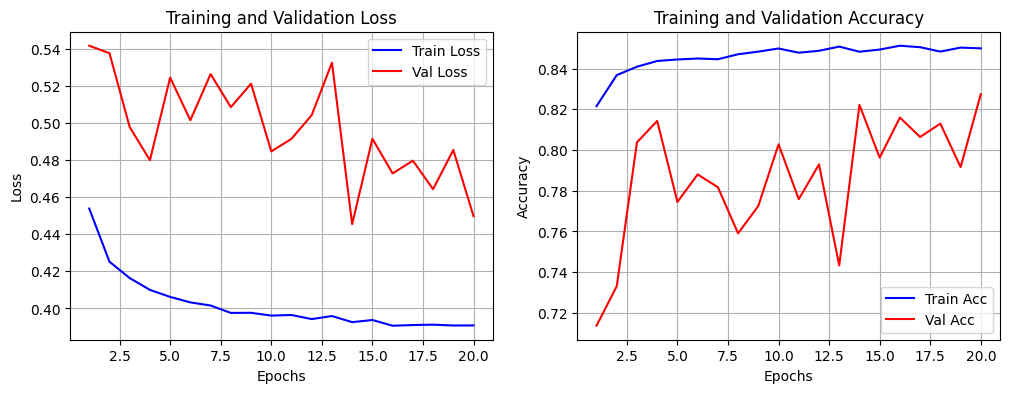

In [70]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm import tqdm

# Настройка устройства
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net.to(device)

# Веса классов и функция потерь
class_weights = torch.tensor([2.0, 8.0]).to(device)  # Переносим веса на GPU/CPU
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)


epochs = 20

# Списки для сохранения метрик и построения графиков
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
}

for epoch in range(epochs):
    # ===== TRAIN =====
    net.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for batch in tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{epochs}"):
        tokens = batch["tokens"].to(device)
        targets = batch["targets"].to(device)

        optimizer.zero_grad()

        outputs = net(tokens)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * tokens.size(0)

        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == targets).sum().item()
        total += targets.size(0)

    epoch_loss = total_loss / total
    epoch_acc = correct / total

    # Сохраняем тренировочные метрики
    history["train_loss"].append(epoch_loss)
    history["train_acc"].append(epoch_acc)

    # ===== VALIDATION =====
    net.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in tqdm(val_dataloader, desc=f"Val {epoch+1}/{epochs}"):
            tokens = batch["tokens"].to(device)
            targets = batch["targets"].to(device)

            outputs = net(tokens)
            loss = criterion(outputs, targets)

            val_loss += loss.item() * tokens.size(0)

            _, predicted = torch.max(outputs.data, 1)
            val_correct += (predicted == targets).sum().item()
            val_total += targets.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    # Сохраняем валидационные метрики
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} - "
        f"Loss: {epoch_loss:.4f} - Acc: {epoch_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}"
    )


# ===== ПОСТРОЕНИЕ ГРАФИКОВ =====
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

# График Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], "b-", label="Train Loss")
plt.plot(epochs_range, history["val_loss"], "r-", label="Val Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# График Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], "b-", label="Train Acc")
plt.plot(epochs_range, history["val_acc"], "r-", label="Val Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


In [71]:
total_loss = 0.0
correct = 0
total = 0

# Для precision/recall
tp = 0  # true positives (предсказано 1, истинно 1)
fp = 0  # false positives (предсказано 1, истинно 0)
fn = 0  # false negatives (предсказано 0, истинно 1)

net.eval()

with torch.no_grad():
    for batch in test_dataloader:
        tokens = batch['tokens'].to(device)
        targets = batch['targets'].to(device)

        outputs = net(tokens)
        loss = criterion(outputs, targets)

        total_loss += loss.item() * tokens.size(0)

        _, predicted = torch.max(outputs, 1)

        correct += (predicted == targets).sum().item()
        total += targets.size(0)

        # Накопление для precision/recall
        tp += ((predicted == 1) & (targets == 1)).sum().item()
        fp += ((predicted == 1) & (targets == 0)).sum().item()
        fn += ((predicted == 0) & (targets == 1)).sum().item()

print(f"Test Loss: {total_loss / total:.4f}, Test Accuracy: {correct / total:.4f}")

# Расчёт precision/recall (с защитой от деления на ноль)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")

#20k 20k
#Test Loss: 7.2299, Test Accuracy: 0.7283
#Precision: 0.1175, Recall: 0.5784, F1: 0.1954

Test Loss: 0.4620, Test Accuracy: 0.8385
Precision: 0.1742, Recall: 0.4902, F1: 0.2571


Confusion Matrix:
[[1450  237]
 [  52   50]]


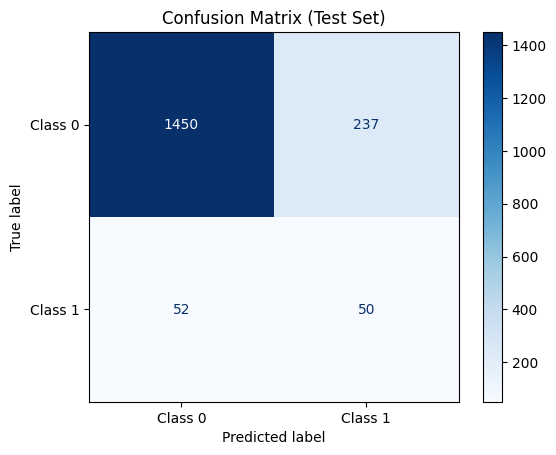

In [72]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

net.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for batch in test_dataloader:
        tokens = batch['tokens'].to(device)
        targets = batch['targets'].to(device)

        outputs = net(tokens)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

# Строим confusion matrix
cm = confusion_matrix(all_targets, all_preds)

print("Confusion Matrix:")
print(cm)

# Визуализация
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()